In [2]:
%matplotlib inline

In [3]:
import numpy as np  # Grids are stored as NumPy Arrays
import gasp         # GASP is what we're testing
import sys          # Needed to query size in bytes of data returned
import h5py
import matplotlib.pyplot as plt
import re

Found 1 CUDA devices in this system
Device 0 : NVIDIA RTX A2000 12GB
Number of SMs       : 26
Max SHMEM per block : 48 KB
Max Opt in shared   : 99 KB
Recommended ngrids  : 3328

Estimated largest L for shared memory code path : 109
(Assumes threadsPerBlock = 32)

Using CUDA device : 0


In [4]:
L = 64
ngrids = 4*gasp.gpu_nsms*32
nsweeps = 50000
nsweeps_small = 10000
beta = 0.54 # 0.53-0.6
h = 0.07 # 0.03-0.1

beta = 0.55
h = 0.082

grid_output_int = 100 # Should be a multiple of mag_output_int (not enforced?)
mag_output_int  = 100 # Note that the collective variable (be it magnetisation or cluster size) is computed only at this interval

In [83]:
%%time
# Run swarm

frac = gasp.run_nucleation_swarm(L, ngrids, nsweeps_small, beta, h, grid_output_int = grid_output_int, mag_output_int=mag_output_int, cv="largest_cluster", up_threshold=0.9*L*L);

 Sweep :       9900, Reached cv = 3686.40 : 2892 , Unresolved :  436
CPU times: user 14.5 s, sys: 575 ms, total: 15 s
Wall time: 51.2 s


In [5]:
def read_attr(ds, name):
    val = ds.attrs.get(name)
    if isinstance(val, bytes):
        val = val.decode('utf-8')
    if val == 'null':
        return np.nan
    return float(val)

# Function to compute magnetisation
def magnetisation(grid):
    return np.sum(grid)/len(grid)**2

# Index function
def index(isnap, igrid):
    grid_idx = isnap*ngrids + igrid
    return grid_idx

def write_training_hdf5(outpath, grids, attrs, L):
    """Append grids and attrs into outpath HDF5 file, creating it if missing.

    If the file exists, ensure header L matches, read current total_saved_grids,
    and append new datasets named grid_<n> with increasing indices.
    """
    # Open file for read/write/create
    with h5py.File(outpath, 'a') as fo:
        # If 'L' doesn't exist create it; otherwise ensure it matches
        if 'L' not in fo:
            fo.create_dataset('L', data=np.int32(L))
        else:
            existing_L = int(fo['L'][()])
            if existing_L != L:
                raise ValueError(f"Existing L={existing_L} does not match provided L={L}")

        # Determine starting index from total_saved_grids
        if 'total_saved_grids' in fo:
            start = int(fo['total_saved_grids'][()])
        else:
            fo.create_dataset('total_saved_grids', data=np.int32(0))
            start = 0

        names = ['magnetisation', 'lclus_size', 'committor', 'committor_error']
        for i in range(grids.shape[0]):
            idx = start + i
            dset = fo.create_dataset(f'grid_{idx}', data=grids[i].astype(np.int8))
            for j, name in enumerate(names):
                val = attrs[i, j]
                if np.isnan(val):
                    dset.attrs[name] = 'null'
                else:
                    dset.attrs[name] = float(val)

        # update total_saved_grids
        fo['total_saved_grids'][()] = np.int32(start + grids.shape[0])
        
# Function to compute magnetisation
def magnetisation(grid):
    return np.sum(grid)/len(grid)**2


In [6]:
%%time

h5path = 'gridstates.hdf5'
print("Opening:", h5path)

with h5py.File(h5path, 'r') as f:
    total_saved = int(f['total_saved_grids'][()])
    L = int(f['L'][()])
    print(f"Header: total_saved_grids={total_saved}, L={L}")

    grids = np.empty((total_saved, L, L), dtype=np.int8)
    attrs = np.empty((total_saved, 4), dtype=np.float64)

    # Collect all datasets and attributes in memory
    sweep_names = sorted(
        (k for k in f.keys() if k.startswith('sweep_')),
        key=lambda x: int(re.search(r'\d+', x).group())
    )

    all_data = []
    all_attrs = []
    for sweep_name in sweep_names:
        grp = f[sweep_name]
        for dname in sorted(grp.keys()):
            ds = grp[dname]
            all_data.append(ds[()])  # dataset bytes
            all_attrs.append([
                read_attr(ds, 'magnetisation'),
                read_attr(ds, 'lclus_size'),
                read_attr(ds, 'committor'),
                read_attr(ds, 'committor_error')
            ])

print(f"Loaded {len(all_data)} datasets and attributes into memory.")

# Convert list of byte arrays into a 2D NumPy array
data_array = np.vstack([np.frombuffer(d, dtype=np.uint8).ravel() for d in all_data])

# Vectorized bit unpacking
nbits = L * L
flat_grids = np.unpackbits(data_array, axis=1, bitorder='little')[:, :nbits]  # only take L*L bits
grids = flat_grids.astype(np.int8) * 2 - 1  # convert 0->-1, 1->+1
grids = grids.reshape((-1, L, L))

# Attributes
attrs = np.array(all_attrs, dtype=np.float64)

print(f"Processed {grids.shape[0]} grids. grids.shape={grids.shape}, attrs.shape={attrs.shape}")

Opening: gridstates.hdf5
Header: total_saved_grids=332800, L=64
Loaded 332800 datasets and attributes into memory.
Processed 332800 grids. grids.shape=(332800, 64, 64), attrs.shape=(332800, 4)
CPU times: user 46.1 s, sys: 881 ms, total: 47 s
Wall time: 47.1 s


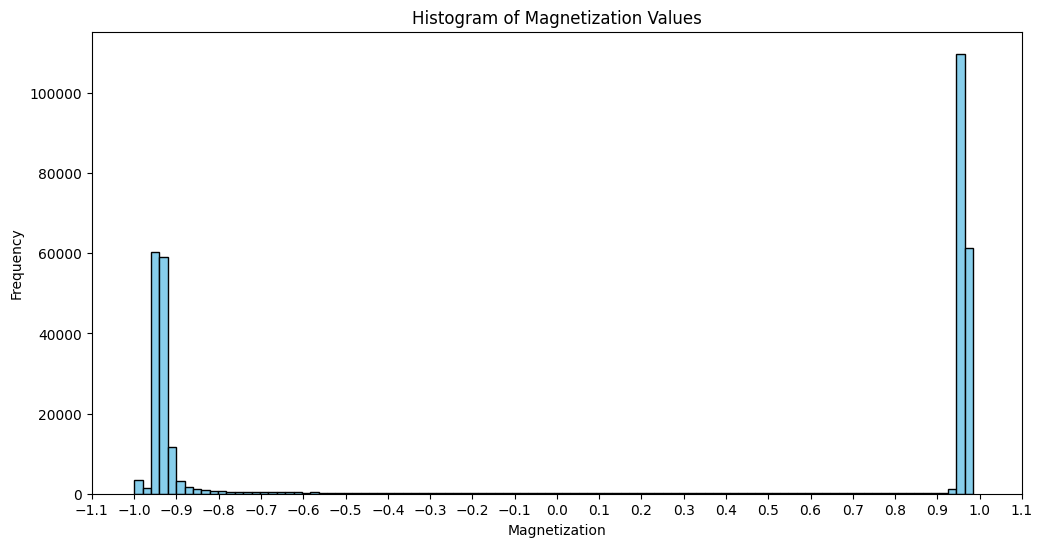

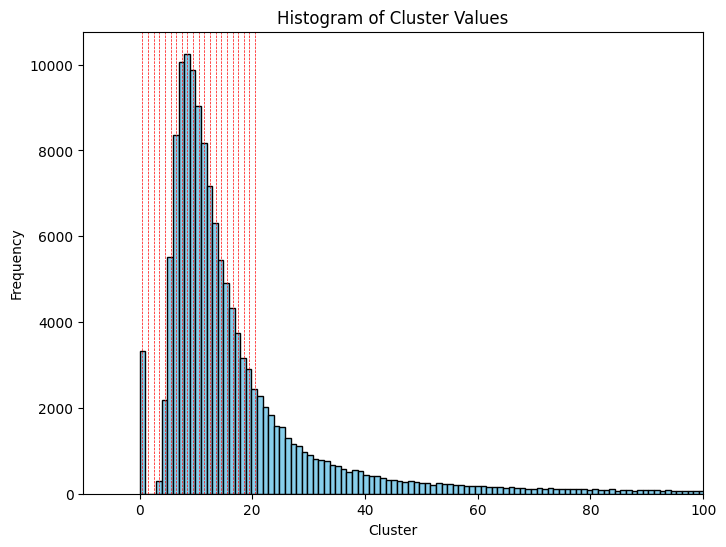

[0.00000000e+00 9.92187500e-01 1.98437500e+00 ... 4.06201562e+03
 4.06300781e+03 4.06400000e+03]


In [7]:
magnetizations = []
cluster = []

# Loop over all snapshots and grids
for attr in attrs:
    magnetizations.append(attr[0])
    cluster.append(attr[1])

bins = 100

# Plot histogram
plt.figure(figsize=(12,6))
plt.hist(magnetizations, bins=bins, color='skyblue', edgecolor='black')
plt.xlabel('Magnetization')
plt.ylabel('Frequency')
plt.title('Histogram of Magnetization Values')
xmin, xmax = plt.xlim()  # get current x-axis limits
plt.xticks(np.arange(round(xmin,1), round(xmax+0.1,1), 0.1))
plt.show()

# Plot histogram
plt.figure(figsize=(8,6))
_, bin_edges, _ = plt.hist(cluster, bins=L*L, color='skyblue', edgecolor='black')
plt.xlabel('Cluster')
plt.ylabel('Frequency')
plt.title('Histogram of Cluster Values')
plt.xlim(-10, 100)
for x in range(0, 21, 1):  # adjust range to match xlim
    x+=0.5
    plt.axvline(x=x, color='red', linestyle='--', lw=0.5)
plt.savefig("clust_hist.pdf")
plt.show()
print(bin_edges)

95 829


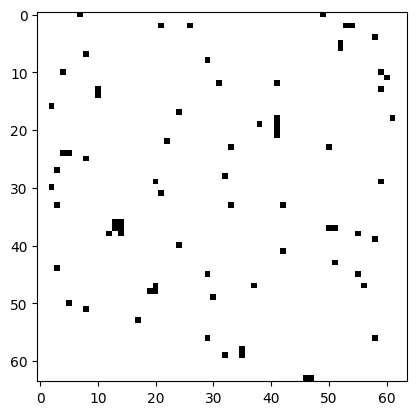

isnap =  95 igrid =  829
magnetisaion :  0.9638671875


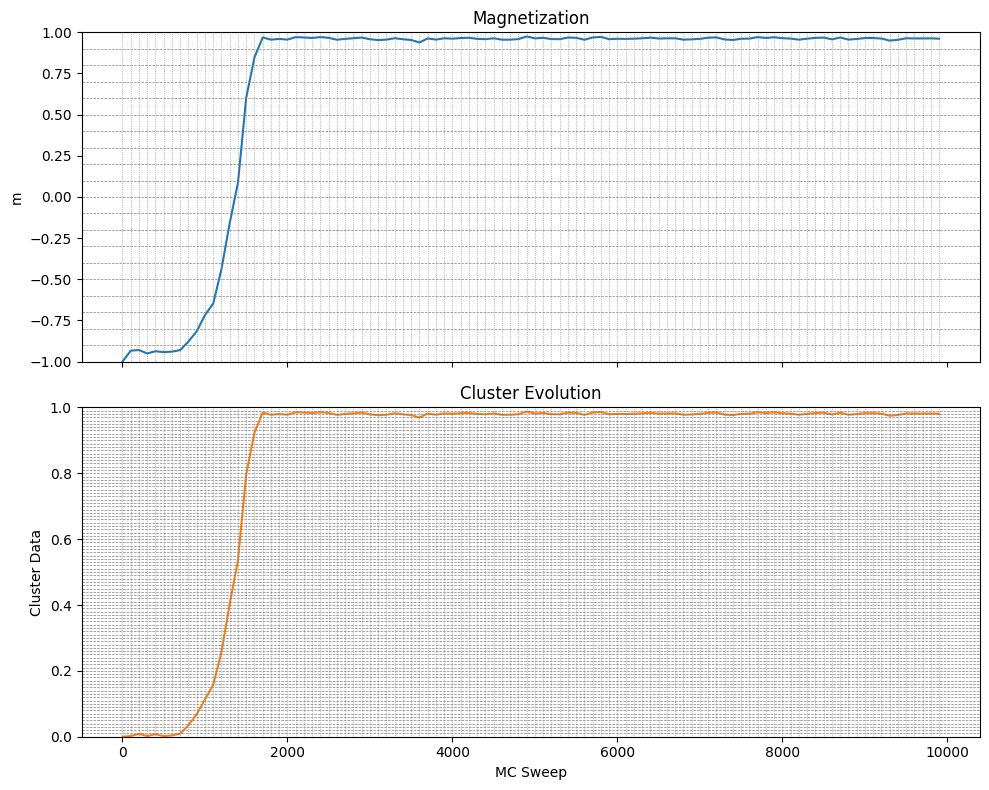

In [8]:
# Visualise a random grid at a random sweep
sweeps = int(grids.shape[0]/ngrids*grid_output_int)
isnap = np.random.randint(0, int(sweeps/grid_output_int))
igrid = np.random.randint(0, ngrids)

print(isnap, igrid)

grid_data = np.array(grids[index(isnap, igrid)])

plt.imshow(grid_data, cmap='grey')
plt.show()
print("isnap = ", isnap, "igrid = ", igrid)
print("magnetisaion : ", magnetisation(grids[index(isnap, igrid)]))

# Compute magnetisation vs time for grid igrid
# Also extract from gasp.magnetisation for comparison
xdata = []
magdata = []
clusterdata = []
for isnap in range(int(sweeps/grid_output_int)):
    xdata.append(isnap*grid_output_int)
    magdata.append(attrs[index(isnap, igrid),0])
    clusterdata.append(attrs[index(isnap, igrid),1]/(L*L))

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# --- Top plot: Magnetization ---
axes[0].plot(xdata, magdata)
axes[0].set_ylabel("m")
axes[0].set_ylim(-1, 1)
for y in np.arange(-1, 1.1, 0.1):
    axes[0].axhline(y=y, color='gray', linestyle='--', linewidth=0.5)
axes[0].set_title("Magnetization")

# --- Bottom plot: Cluster Data ---
axes[1].plot(xdata, clusterdata, color="tab:orange")
axes[1].set_xlabel("MC Sweep")
axes[1].set_ylabel("Cluster Data")
axes[1].set_ylim(0, 1)
for y in np.arange(0, 1.1, 0.01):
    axes[1].axhline(y=y, color='gray', linestyle='--', linewidth=0.5)
axes[1].set_title("Cluster Evolution")

# --- Add vertical lines at sweep ticks across both plots ---
for x in xdata:
    axes[0].axvline(x=x, color='gray', linestyle=':', linewidth=0.5)
    axes[1].axvline(x=x, color='gray', linestyle=':', linewidth=0.5)

plt.tight_layout()
plt.show()

Selected 8166 Percentage of total 2 %


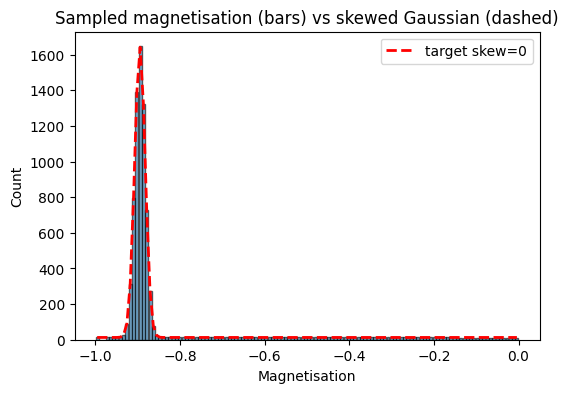

In [46]:
# --- GAUSSIAN ---
target_mag = -0.895
tolerance = 0.075
sigma = tolerance / 6
skew = 0   # -1 left tilt, +1 right tilt, 0 symmetric

# --- UNIFORM ---
mag_min = -1
mag_max = 0
samples_per_bin = 1

# --- PARAMETERS ---
num_bins = 128
max_samples = 8192

mag_vals = np.array([magnetisation(g) for g in grids])
mask = (mag_vals >= mag_min) & (mag_vals <= mag_max)
candidates, cand_mag = np.where(mask)[0], mag_vals[mask]

if len(candidates) == 0:
    sample_idx = np.array([], dtype=int)
else:
    bins = np.linspace(mag_min, mag_max, num_bins + 1)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    bin_counts, _ = np.histogram(cand_mag, bins=bins)

    nonempty = bin_counts > 0
    if not np.any(nonempty):
        sample_idx = np.array([], dtype=int)
    else:
        # z = standardized distance
        z = (bin_centers - target_mag) / sigma
        
        # skewed Gaussian-like pdf, always > 0 at both ends
        desired_pdf = np.exp(-0.5 * z**2) * (1 + np.tanh(skew * z))
        
        # clip to nonnegative and mask empty bins
        desired_pdf = np.clip(desired_pdf, 1e-12, None)
        desired_pdf *= nonempty.astype(float)
        desired_pdf += 1/num_bins
        
        # normalize into a probability distribution
        if desired_pdf.sum() == 0:
            desired_mass = nonempty.astype(float) / nonempty.sum()
        else:
            desired_mass = desired_pdf / desired_pdf.sum()

        # total samples
        total_candidates = len(candidates)
        gpu_multiple, cap = gasp.gpu_nsms, max_samples
        target_samples = min(total_candidates - (total_candidates % gpu_multiple),
                             cap - (cap % gpu_multiple),
                             total_candidates)

        desired_counts_float = desired_mass * target_samples
        desired_counts = np.floor(desired_counts_float).astype(int)

        remaining = target_samples - desired_counts.sum()

        if remaining > 0:
            frac = desired_counts_float - desired_counts
            order = np.argsort(-frac)
            for i in order:
                if remaining == 0: break
                if desired_counts[i] < bin_counts[i]:
                    desired_counts[i] += 1
                    remaining -= 1
        
        chosen = []
        for i in range(num_bins):
            k = desired_counts[i]
            if k <= 0: continue
            if i < num_bins - 1:
                bin_mask = (cand_mag >= bins[i]) & (cand_mag < bins[i+1])
            else:
                bin_mask = (cand_mag >= bins[i]) & (cand_mag <= bins[i+1])
            idxs_in_bin = candidates[bin_mask]
            if len(idxs_in_bin) == 0: continue
            sel = np.random.choice(idxs_in_bin, size=k, replace=len(idxs_in_bin) < k)
            chosen.append(sel)

        sample_idx = np.hstack(chosen) if chosen else np.array([], dtype=int)

# Sort
if sample_idx.size > 0:
    sample_attrs = attrs[sample_idx]
    order = np.argsort(sample_attrs[:, 1])
    sample_idx = sample_idx[order]
    sample_grids = [grids[i] for i in sample_idx]
    sample_attrs = sample_attrs[order]
else:
    sample_grids = []
    sample_attrs = np.empty((0, attrs.shape[1]))

print("Selected", len(sample_grids),
      "Percentage of total", int(len(sample_grids) / len(grids) * 100), "%")

# Plot
plt.figure(figsize=(6,4))
plt.hist([magnetisation(g) for g in sample_grids], bins=bins,
         edgecolor='black', rwidth=0.9, alpha=0.6)

expected_counts = (desired_mass / desired_mass.sum()) * len(sample_idx)
plt.plot(bin_centers, expected_counts, 'r--', linewidth=2, label=f'target skew={skew}')
plt.xlabel("Magnetisation")
plt.ylabel("Count")
plt.title(f"Sampled magnetisation (bars) vs skewed Gaussian (dashed)")
plt.legend(); plt.show()


In [48]:
%%time

# For purposes of dividing up multiple committor calcs onto a single GPU, it is useful to reference the number of streaming multiprocessors
# (SMs) on the GPU we're working with. We should run a maximum of gpu_nsms x 4 grids at once on each GPU
gpu_nsms = gasp.gpu_nsms
ngrids = 4*gasp.gpu_nsms*32

gpu_nsms = int(gpu_nsms/2)

for cluster in [5.5]:
    print(f"Cluster: {cluster}")
    for i in range(int(len(sample_idx)/gpu_nsms)):
        print("Running iteration ", i, "of ", int(len(sample_idx)/gpu_nsms-1))
        # Calculate committor of all these snapshots using 1/gpu_nsms of a GPU for each
        gridlist = sample_grids[i*gpu_nsms:(i+1)*gpu_nsms]
        attrlist = sample_attrs[i*gpu_nsms:(i+1)*gpu_nsms]

        if attrlist[:,1].min() < 20:
            mag_output_int = 1
        elif attrlist[:,1].min() < 80:
            mag_output_int = 10
        else:
            mag_output_int = 100
            
        pBfast = np.array(gasp.run_committor_calc(L, ngrids, nsweeps, beta, h, grid_output_int=50000, mag_output_int=mag_output_int, grid_input="NumPy", grid_array=gridlist, cv="largest_cluster", dn_threshold=cluster, up_threshold=0.9*L*L))
        attrlist[:, 2] = pBfast[:, 0] # Save committor
        attrlist[:, 3] = pBfast[:, 1] # Save committor error
        write_training_hdf5("training_gridstates.hdf5", np.array(gridlist), attrlist, L)

Cluster: 5.5
Running iteration  0 of  627
 Sweep :          0, Reached cv =   5.50 : 3328 , Reached cv = 3686.40 :    0 , Unresolved :    0
Running iteration  1 of  627
 Sweep :          0, Reached cv =   5.50 : 3328 , Reached cv = 3686.40 :    0 , Unresolved :    0
Running iteration  2 of  627
 Sweep :        744, Reached cv =   5.50 : 3325 , Reached cv = 3686.40 :    3 , Unresolved :    0
Running iteration  3 of  627
 Sweep :       1103, Reached cv =   5.50 : 3316 , Reached cv = 3686.40 :   12 , Unresolved :    0
Running iteration  4 of  627
 Sweep :       1151, Reached cv =   5.50 : 3308 , Reached cv = 3686.40 :   20 , Unresolved :    0
Running iteration  5 of  627
 Sweep :        912, Reached cv =   5.50 : 3302 , Reached cv = 3686.40 :   26 , Unresolved :    0
Running iteration  6 of  627
 Sweep :       1321, Reached cv =   5.50 : 3295 , Reached cv = 3686.40 :   33 , Unresolved :    0
Running iteration  7 of  627
 Sweep :       1046, Reached cv =   5.50 : 3286 , Reached cv = 3686.4

In [49]:
# --- Step 1: Read everything into memory ---
with h5py.File("training_gridstates.hdf5", 'r') as f:
    total_saved = int(f['total_saved_grids'][()])
    L = int(f['L'][()])
    print(f"Header: total_saved_grids={total_saved}, L={L}")

    # Collect raw grids and attrs in memory
    all_grids = []
    all_attrs = []

    for grid_name in sorted(k for k in f.keys() if k.startswith('grid_')):
        grp = f[grid_name]
        all_grids.append(grp[()])  # copy grid array into memory
        all_attrs.append([
            read_attr(grp, 'magnetisation'),
            read_attr(grp, 'lclus_size'),
            read_attr(grp, 'committor'),
            read_attr(grp, 'committor_error')
        ])

print(f"Loaded {len(all_grids)} grids and attributes into memory.")

# --- Step 2: Convert into NumPy arrays ---
training_grids = np.array(all_grids, dtype=np.int8).reshape((-1, L, L))
training_attrs = np.array(all_attrs, dtype=np.float64)

print(f"Final arrays: training_grids.shape={training_grids.shape}, training_attrs.shape={training_attrs.shape}")


Header: total_saved_grids=8164, L=64
Loaded 8164 grids and attributes into memory.
Final arrays: training_grids.shape=(8164, 64, 64), training_attrs.shape=(8164, 4)


Minimum count in any bin: 46


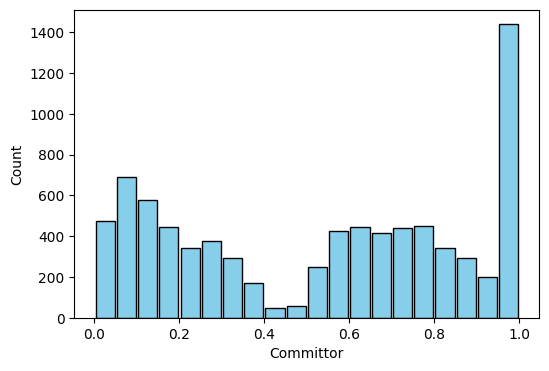

In [50]:
# Define bins
bins = np.linspace(0, 1, 21)
mag_values = training_attrs[:, 2]

# Compute histogram counts
counts, _ = np.histogram(mag_values, bins=bins)
print("Minimum count in any bin:", counts.min())

# Plot histogram
plt.figure(figsize=(6,4))
plt.hist(mag_values, bins=bins, edgecolor='black', rwidth=0.9, color='skyblue')
plt.xlabel("Committor")
plt.ylabel("Count")
plt.show()

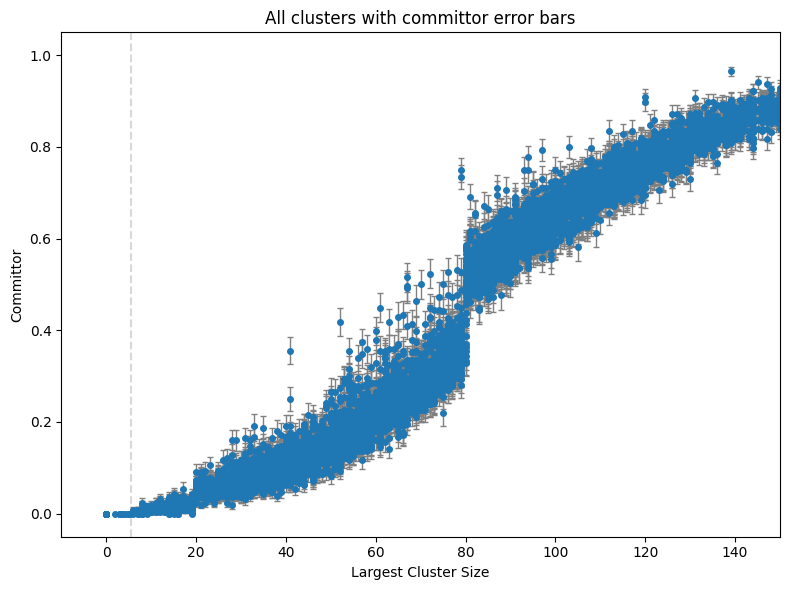

In [51]:
x = training_attrs[:, 1]
y = training_attrs[:, 2]
yerr = training_attrs[:, 3]

plt.figure(figsize=(8,6))

# Plot all points with error bars
plt.errorbar(x, y, yerr=yerr, fmt='o', markersize=4, alpha=1, ecolor='gray', elinewidth=1, capsize=2)

# Vertical lines as reference
#for xv in range(0, 151, 2):
    #plt.axvline(x=xv, color='grey', linestyle='--', alpha=0.3)

plt.axvline(x=5.5, color='grey', linestyle='--', alpha=0.3)

plt.xlabel("Largest Cluster Size")
plt.ylabel("Committor")
plt.title("All clusters with committor error bars")
plt.xlim(-10, 150)
plt.tight_layout()
plt.savefig("cluster_with_errorbars.pdf")
plt.show()

In [103]:
# Define bins
bins = np.linspace(0, 1, 21)
mag_values = training_attrs[:, 2]

# Assign each sample to a bin
bin_indices = np.digitize(mag_values, bins) - 1

# Find minimum bin count
counts = np.bincount(bin_indices, minlength=len(bins)-1)
min_count = counts.min()
min_count = min(min_count, 500)
print("Minimum count in any bin:", min_count)

# Collect uniformly sampled indices
rng = np.random.default_rng(42)
selected_indices = []
for b in range(len(bins) - 1):
    bin_idx = np.where(bin_indices == b)[0]
    if len(bin_idx) >= min_count:
        chosen = rng.choice(bin_idx, size=min_count, replace=False)
        selected_indices.extend(chosen)

selected_indices = np.array(selected_indices)

# Apply filtering
uniform_grids = training_grids[selected_indices]
uniform_attrs = training_attrs[selected_indices]

print(f"Uniform dataset size: {len(uniform_grids)}")

# Plot histogram of filtered data
plt.figure(figsize=(6,4))
plt.hist(uniform_attrs[:, 2], bins=bins, edgecolor='black', rwidth=0.9, color='skyblue')
plt.xlabel("Committor")
plt.ylabel("Count (uniform)")
plt.show()

Minimum count in any bin: 0
[]


IndexError: arrays used as indices must be of integer (or boolean) type

In [ ]:
write_training_hdf5("training_gridstates_uniform.hdf5", uniform_grids, uniform_attrs, L)